In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Q1. Data Loading & Understanding**

a) Load the dataset into Python.

b) Display the first 5 rows.

c) Check the shape of the dataset.

d) Display the data types of each column.

In [26]:
df = pd.read_excel('/content/loan_approval.xlsx')
df.head()

,name,city,income,credit_score,loan_amount,years_employed,points,loan_approved
0,Allison Hill,East Jill,113810,389,39698,27,50,False
1,Brandon Hall,New Jamesside,44592,729,15446,28,55,False
2,Rhonda Smith,Lake Roberto,33278,584,11189,13,45,False
3,Gabrielle Davis,West Melanieview,127196,344,48823,29,50,False
4,Valerie Gray,Mariastad,66048,496,47174,4,25,False


In [27]:
df.shape

(2000, 8)

In [28]:
df.dtypes

,0
name,object
city,object
income,int64
credit_score,int64
loan_amount,int64
years_employed,int64
points,int64
loan_approved,bool


**Q2. Data Cleaning**

a) Check for missing values in the dataset.

b) Handle missing values appropriately.

c) Identify categorical columns present in the dataset

In [29]:
df.isnull().sum()

,0
name,0
city,0
income,0
credit_score,0
loan_amount,0
years_employed,0
points,0
loan_approved,0


There are no null or missing values in the dataset.

In [30]:
df.select_dtypes(include='object').columns

Index(['name', 'city'], dtype='object')

**Q3. Exploratory Data Analysis (EDA)**

a) Plot the distribution of the target variable.

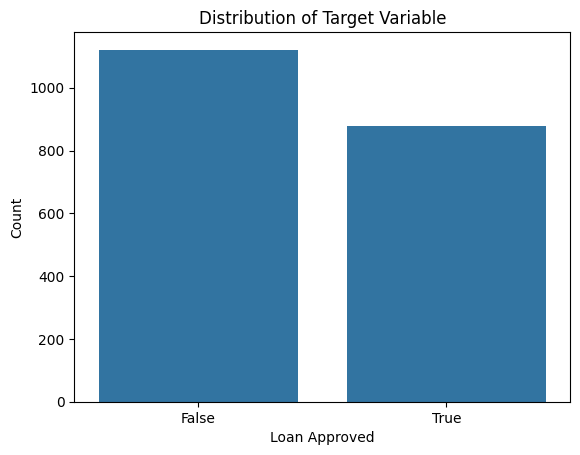

In [31]:
sns.countplot(x= 'loan_approved',data = df)
plt.title('Distribution of Target Variable')
plt.xlabel('Loan Approved')
plt.ylabel('Count')
plt.show()

**b) Analyze the relationship between one numerical feature and the target variable.**

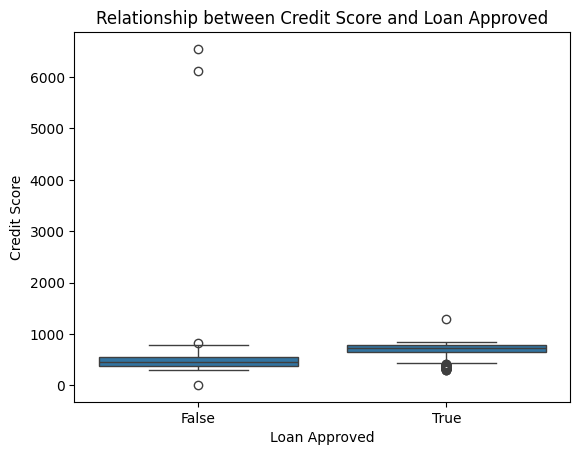

In [32]:
sns.boxplot(x='loan_approved', y='credit_score', data=df)
plt.title('Relationship between Credit Score and Loan Approved')
plt.xlabel('Loan Approved')
plt.ylabel('Credit Score')
plt.show()

**c) Analyze the relationship between Years of Employment and the target variable.**

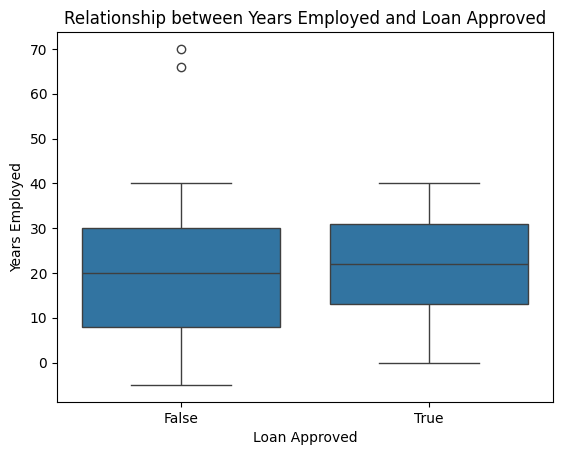

In [33]:
sns.boxplot(x='loan_approved', y='years_employed', data=df)
plt.title('Relationship between Years Employed and Loan Approved')
plt.xlabel('Loan Approved')
plt.ylabel('Years Employed')
plt.show()

**Q4. Outlier Detection and Treatment**

a) Detect outliers in numerical columns using the IQR method.

In [34]:
numerical_cols = ['income', 'credit_score', 'loan_amount', 'years_employed', 'points']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(col, ':' , len(outliers), 'outliers')

income : 0 outliers
credit_score : 3 outliers
loan_amount : 0 outliers
years_employed : 2 outliers
points : 0 outliers


**b) Treat outliers using capping techniques**

In [35]:
for col in numerical_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df[col] = df[col].clip(lower_bound,upper_bound)

**Q5. Convert target variables into numerical format suitable for model building and drop unnecessary columns.**

In [36]:
df['loan_approved']=df['loan_approved'].astype(int)

In [37]:
df.drop(columns=['name','city'],inplace=True)

In [38]:
df.head()

,income,credit_score,loan_amount,years_employed,points,loan_approved
0,113810,389.0,39698,27.0,50,0
1,44592,729.0,15446,28.0,55,0
2,33278,584.0,11189,13.0,45,0
3,127196,344.0,48823,29.0,50,0
4,66048,496.0,47174,4.0,25,0


**Q6. Feature Selection and Data Splitting**

a) Separate independent variables (X) and dependent variable (y)

In [39]:
x= df.drop(columns='loan_approved')
y=df['loan_approved']

**b) Split the dataset into training and testing sets**

In [40]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42)

**Q7. Apply feature scaling to the dataset using StandardScaler**

In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

**Q8. Logistic Regression Model Building**

**a) Train a Logistic Regression model.**

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = LogisticRegression()
model.fit(x_train_scaled, y_train)



LogisticRegression()

**b) Predict the output for test data.**

In [43]:
y_pred = model.predict(x_test_scaled)
print(y_pred)

[0 1 1 1 1 1 0 1 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 1 1 0 1 0 0 1 0 1 0 0 0
 0 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 1 0 1 1 0 0 1 0
 1 0 1 1 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 0 1 0 1 1 1 1 0 0 1 0 0 0 0 1 0 0
 0 0 0 0 0 1 0 0 0 1 1 0 0 1 1 1 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 1 0 0 1 0 1
 0 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 1 0 1 1 0 0 1 0 0 0 1 0 1 1 0 1 1 1 1 1 0
 0 1 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 0 1 1 1 1 0 0 1 1 0 1 0 0 1 1 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 0 1
 1 0 1 0 0 1 0 0 1 0 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0 0 1 1 1 1 1 0 0 0 1 1
 1 0 1 1 0 1 0 0 0 0 0 1 0 1 1 0 1 1 0 1 1 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 1
 0 0 0 1 1 1 1 0 0 1 1 0 0 1 1 0 1 0 1 0 1 0 1 0 1 1 0 1 1 1 1 0 1 1 1 0 1
 1 1 0 1 1 0 0 1 0 0 1 0 0 0 1 0 1 1 1 1 1 0 1 1 1 0 0 1 1 1]


**Q9. Model Evaluation – Confusion Matrix**

**a) Generate the confusion matrix.**

In [44]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[217   0]
 [  0 183]]


**b) Interpret the results.**

The confusion matrix is:

[[217, 0],
[0, 183]]

- True Negative (TN) = 217
- False Positive (FP) = 0
- False Negative (FN) = 0
- True Positive (TP) = 183

The model correctly classified all 400 test samples. There are no false positive or false negative predictions, so the model shows 100% accuracy on this test set.

**Q10. Model Evaluation – ROC Curve & AUC**

**a) Plot the ROC curve.**

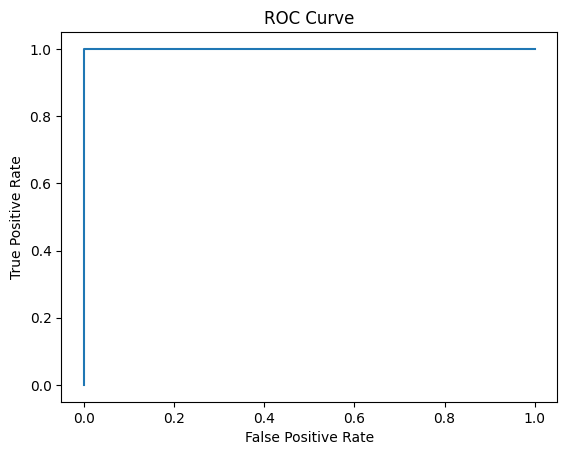

In [45]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob=model.predict_proba(x_test_scaled)[:,1]

fpr,tpr,thresholds=roc_curve(y_test,y_prob)

plt.plot(fpr,tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve' )
plt.show()

**b) Calculate the AUC score**

In [46]:
auc = roc_auc_score(y_test, y_prob)
print("AUC Score:", auc)

AUC Score: 1.0
